# Apprendre les SVM avec des images

Un parcours guidé de classification avec les machines à vecteurs de support (SVM), de la petite image de chiffre à l'image satellite.

## Objectifs et parcours

À la fin de ce notebook, vous saurez préparer des images pour un classifieur, entraîner un SVM avec scikit-learn et interpréter ses performances.

Nous avançons en trois étapes :
1. Reconnaître des chiffres écrits à la main avec un jeu de données intégré à scikit-learn.
2. Découvrir l'effet du prétraitement, de la réduction de dimension et des paramètres du SVM avec un jeu de visages facultatif.
3. Relier ces notions à une classification d'occupation des sols dans QGIS/Orfeo ToolBox (OTB).

**Prérequis :** connaître les bases de Python, des tableaux NumPy et de la classification supervisée. La première partie s'exécute dans le notebook ; la dernière nécessite QGIS et OTB installés séparément.

### Bibliothèques

Ces bibliothèques fournissent les tableaux, les graphiques, les jeux de données d'exemple et les outils SVM de scikit-learn.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
from sklearn import datasets, svm
from sklearn.decomposition import PCA
from sklearn.metrics import classification_report
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split

np.random.seed(31415)

## Partie 1 - Reconnaître des chiffres manuscrits

Nous commençons par le jeu `digits` inclus dans scikit-learn. Chaque exemple est une petite image en niveaux de gris, et son étiquette indique le chiffre représenté.

**Question métier simplifiée :** à partir des pixels d'une image, peut-on prédire le chiffre de 0 à 9 ?

In [2]:
dataset = datasets.load_digits()
images = dataset.images
labels = dataset.target

print(f"Nombre d'images : {len(images)}")
print(f"Taille d'une image : {images.shape[1]} x {images.shape[2]} pixels")
print(f"Valeur des pixels : de {images.min()} à {images.max()}")
print(f"Classes présentes : {np.unique(labels)}")

Nombre d'images : 1797
Taille d'une image : 8 x 8 pixels
Valeur des pixels : de 0.0 à 16.0
Classes présentes : [0 1 2 3 4 5 6 7 8 9]


### Observer quelques images

Avant d'entraîner le modèle, regardons des exemples et leurs étiquettes. Chaque pixel est une mesure numérique ; l'image complète sera ensuite représentée par un vecteur de pixels.

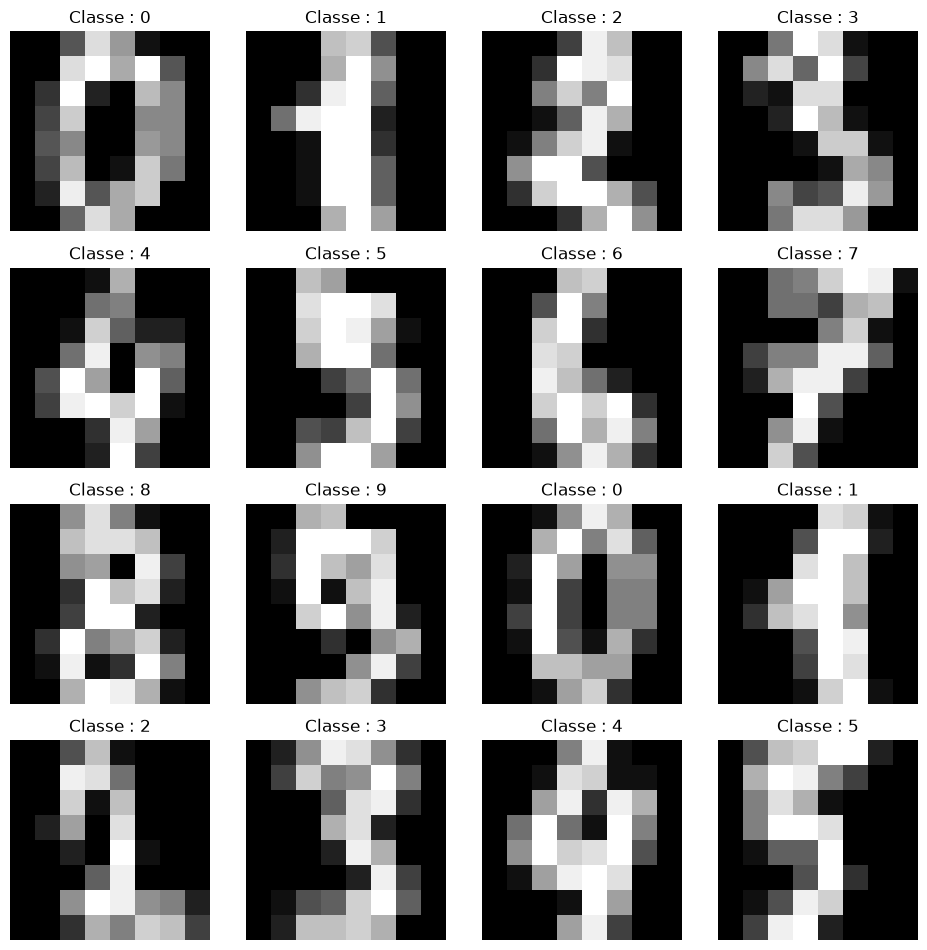

In [3]:
def plot(images, labels, cmap="gray", normalize=False, n_images=16):
    images = np.asarray(images)
    n_images = min(n_images, len(images))
    n_columns = 4
    n_rows = int(np.ceil(n_images / n_columns))
    figure, axes = plt.subplots(
        n_rows, n_columns, figsize=(2.4 * n_columns, 2.4 * n_rows)
    )

    for axis, image, label in zip(axes.flat, images[:n_images], labels[:n_images]):
        if normalize and image.max() > 1:
            image = image / 255.0
        axis.imshow(image, cmap=cmap)
        axis.set_title(f"Classe : {label}")
        axis.axis("off")

    for axis in axes.flat[n_images:]:
        axis.axis("off")

    figure.tight_layout()
    plt.show()


plot(images, labels)

### Transformer une image en vecteur de caractéristiques

Un SVM reçoit un tableau de nombres, pas une image en deux dimensions. On aplatit donc chaque image 8 × 8 en un vecteur de 64 valeurs : chaque pixel devient une caractéristique (`feature`). La cible `y` reste le chiffre à reconnaître.

In [4]:
def reshape(images):
    """Convertit un lot d'images en matrice (images, pixels)."""
    images = np.asarray(images)
    if images.ndim < 2:
        raise ValueError("images doit contenir un lot d'images")
    return images.reshape(images.shape[0], -1)


X = reshape(images)
y = labels
print(f"Forme du lot d'images : {images.shape}")
print(f"Forme de X (observations, caractéristiques) : {X.shape}")
print(f"Forme de y (étiquettes) : {y.shape}")

Forme du lot d'images : (1797, 8, 8)
Forme de X (observations, caractéristiques) : (1797, 64)
Forme de y (étiquettes) : (1797,)


### Séparer entraînement et test

Le jeu d'entraînement sert à apprendre les frontières de décision. Le jeu de test est gardé à l'écart pour vérifier ensuite si le modèle généralise à des images qu'il n'a pas vues. `stratify=y` conserve dans les deux lots une répartition similaire des chiffres.

In [5]:
def split(X, y, ratio=0.7, random_state=42):
    """Sépare X/y en conservant la même proportion de chaque classe."""
    if not 0 < ratio < 1:
        raise ValueError("ratio doit être compris entre 0 et 1")
    return train_test_split(
        X,
        y,
        train_size=ratio,
        random_state=random_state,
        stratify=y,
    )


X_train, X_test, y_train, y_test = split(X, y)
print(f"Entraînement : {X_train.shape[0]} images")
print(f"Test : {X_test.shape[0]} images")
print("Proportion des classes conservée grâce à la stratification.")

Entraînement : 1257 images
Test : 540 images
Proportion des classes conservée grâce à la stratification.


### Entraîner un premier SVM

Un SVM cherche une frontière qui sépare les classes en gardant une marge aussi large que possible. Les exemples proches de la frontière, appelés **vecteurs de support**, influencent particulièrement cette séparation.

La standardisation met les caractéristiques sur des échelles comparables. Elle est incluse dans un `Pipeline` : à chaque validation, elle sera ajustée uniquement sur les données d'entraînement. Avec `kernel="linear"`, le SVM commence par apprendre une frontière linéaire ; `C` règle le compromis entre marge large et erreurs d'entraînement.

In [6]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


def train_svm(X_train, y_train, kernel="linear", C=1):
    """Construit et entraîne un pipeline de standardisation et de SVM."""
    model = Pipeline(
        steps=[
            ("standardisation", StandardScaler()),
            ("svm", svm.SVC(kernel=kernel, C=C)),
        ]
    )
    return model.fit(X_train, y_train)


model = train_svm(X_train, y_train)
print("Noyau : linéaire | C : 1")
print("StandardScaler et SVC sont entraînés sur le jeu d'entraînement uniquement.")

Noyau : linéaire | C : 1
StandardScaler et SVC sont entraînés sur le jeu d'entraînement uniquement.


### Évaluer les prédictions

On prédit les classes des images du jeu de test sans réentraîner le modèle. La comparaison entre ces prédictions et les vraies étiquettes permet ensuite de mesurer les erreurs.

In [7]:
def test_svm(X_test, model):
    """Retourne les classes prédites pour les observations de test."""
    return model.predict(X_test)


prediction = test_svm(X_test, model)
print(f"Nombre de prédictions : {len(prediction)}")

Nombre de prédictions : 540


### Lire les métriques et les erreurs

- **Précision** : parmi les images prédites comme un chiffre donné, quelle proportion correspond à ce chiffre ?
- **Rappel** : parmi les images qui représentent réellement ce chiffre, quelle proportion le modèle retrouve ?
- **F1-score** : compromis entre précision et rappel.
- **Matrice de confusion** : les lignes indiquent le vrai chiffre et les colonnes le chiffre prédit ; les valeurs sur la diagonale sont les bonnes prédictions.

Rapport de classification (une ligne par chiffre) :
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        54
           1       0.92      0.98      0.95        55
           2       1.00      1.00      1.00        53
           3       0.98      0.98      0.98        55
           4       1.00      1.00      1.00        54
           5       1.00      0.96      0.98        55
           6       0.98      0.98      0.98        54
           7       0.98      1.00      0.99        54
           8       1.00      0.88      0.94        52
           9       0.95      1.00      0.97        54

    accuracy                           0.98       540
   macro avg       0.98      0.98      0.98       540
weighted avg       0.98      0.98      0.98       540



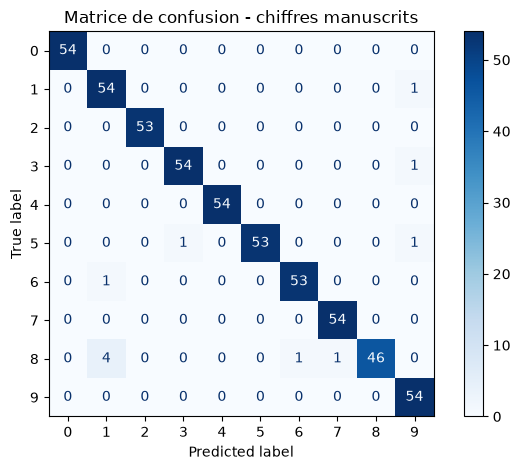

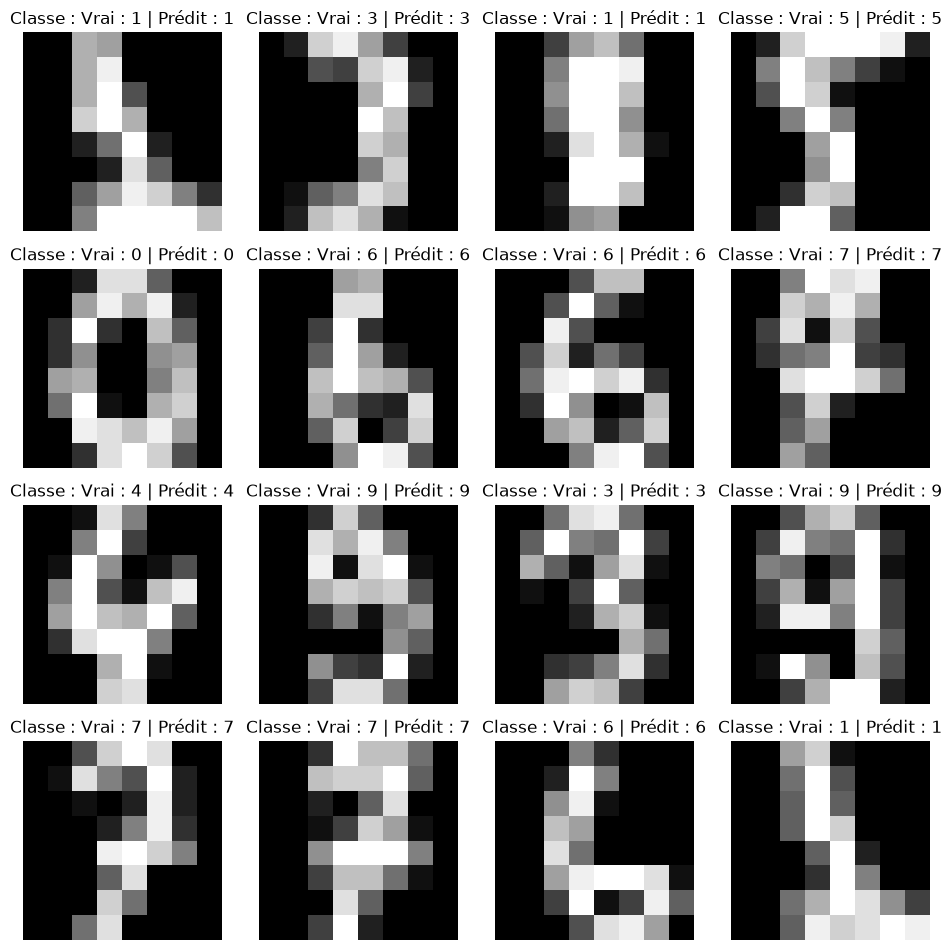

In [8]:
from sklearn.metrics import ConfusionMatrixDisplay


def stats(y_true, prediction):
    print("Rapport de classification (une ligne par chiffre) :")
    print(
        classification_report(
            y_true,
            prediction,
            labels=np.arange(10),
            zero_division=0,
        )
    )

    ConfusionMatrixDisplay.from_predictions(
        y_true,
        prediction,
        labels=np.arange(10),
        display_labels=np.arange(10),
        cmap="Blues",
        values_format="d",
    )
    plt.title("Matrice de confusion - chiffres manuscrits")
    plt.tight_layout()
    plt.show()


stats(y_test, prediction)

labels_comparaison = [
    f"Vrai : {vrai} | Prédit : {prevu}"
    for vrai, prevu in zip(y_test, prediction)
]
images_test = X_test.reshape((-1, *dataset.images.shape[1:]))
plot(images_test, labels_comparaison, n_images=16)

### Interpréter le premier résultat

Sur ce partage entraînement/test, le SVM linéaire obtient environ **98 % d'accuracy**. La plupart des valeurs de la matrice de confusion sont sur la diagonale : la majorité des chiffres sont correctement reconnus. Les valeurs hors diagonale montrent les confusions ; ici, le chiffre `8` est le plus difficile à reconnaître (rappel de `0,88`).

C'est un bon premier résultat sur le jeu `digits`, mais pas une preuve que le SVM reconnaîtra aussi bien des chiffres réels ou des images différentes. La performance dépend du jeu de données et de la manière dont les images sont préparées. Pour le confirmer, on comparera plusieurs noyaux et on gardera le test final à part.

### À quoi correspondent les caractéristiques ?

Après l'aplatissement, une caractéristique correspond à l'intensité d'un pixel. Une image de `8 × 8` contient donc **64 caractéristiques**. Les bords de l'image sont souvent noirs, mais il faut le vérifier expérimentalement avant de conclure qu'on peut les supprimer : ils peuvent parfois aider à distinguer des chiffres.

### Sélectionner des pixels : pourquoi et comment ?

La sélection de caractéristiques cherche à garder les pixels les plus utiles à la séparation des chiffres. `RFECV` (Recursive Feature Elimination with Cross-Validation) retire progressivement des caractéristiques et utilise la validation croisée pour choisir combien en conserver.

**Important :** on ajuste cette sélection uniquement sur `X_train`. Si on utilise le test pour choisir les pixels, le résultat final devient trop optimiste. La carte suivante permettra de visualiser quels pixels ont été conservés.

### Expérience facultative : choisir le nombre de pixels

La cellule suivante compare plusieurs tailles de sous-ensemble par validation croisée, exclusivement sur les données d'entraînement. Pour limiter le temps de calcul, `step=4` retire quatre pixels à chaque itération.

Nombre de pixels retenus : 36 sur 64
Accuracy CV maximale : 0.944


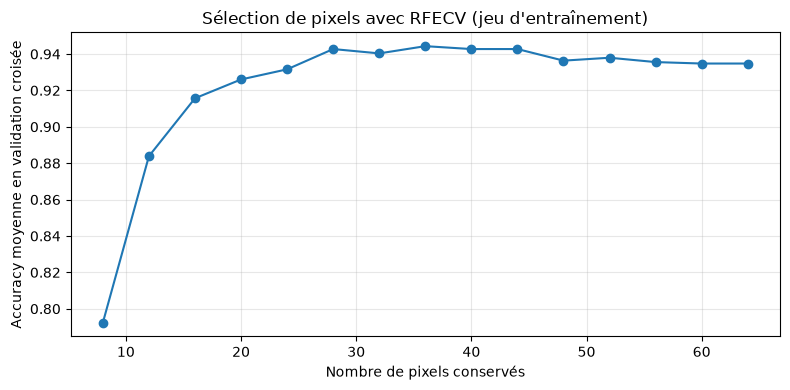

In [9]:
from sklearn.feature_selection import RFECV
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

cv_selection = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
estimateur_selection = Pipeline(
    steps=[
        ("standardisation", StandardScaler()),
        ("classifieur", LinearSVC(C=1, dual="auto", max_iter=5000, random_state=42)),
    ]
)

selection = RFECV(
    estimator=estimateur_selection,
    step=4,
    min_features_to_select=8,
    cv=cv_selection,
    scoring="accuracy",
    n_jobs=-1,
    importance_getter="named_steps.classifieur.coef_",
)
selection.fit(X_train, y_train)

print(f"Nombre de pixels retenus : {selection.n_features_} sur {X_train.shape[1]}")
print(f"Accuracy CV maximale : {selection.cv_results_['mean_test_score'].max():.3f}")

plt.figure(figsize=(8, 4))
plt.plot(
    selection.cv_results_["n_features"],
    selection.cv_results_["mean_test_score"],
    marker="o",
)
plt.xlabel("Nombre de pixels conservés")
plt.ylabel("Accuracy moyenne en validation croisée")
plt.title("Sélection de pixels avec RFECV (jeu d'entraînement)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Visualiser les pixels retenus

RFECV enregistre un masque indiquant les caractéristiques conservées. On le remet en forme comme l'image d'origine pour voir où se trouvent les pixels sélectionnés.

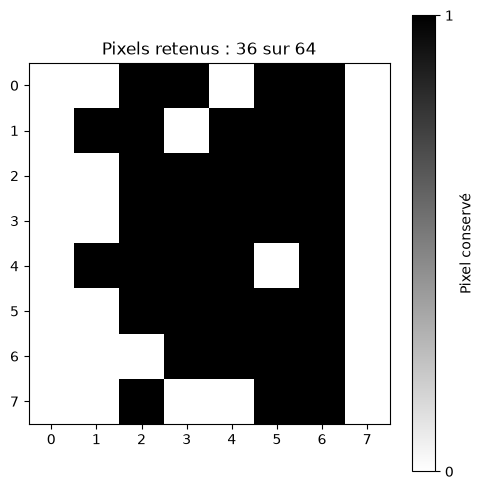

In [10]:
masque_pixels = selection.support_.reshape(images.shape[1:])

plt.figure(figsize=(5, 5))
plt.imshow(masque_pixels, cmap="gray_r", vmin=0, vmax=1)
plt.title(f"Pixels retenus : {selection.n_features_} sur {X.shape[1]}")
plt.xticks(range(images.shape[2]))
plt.yticks(range(images.shape[1]))
plt.colorbar(ticks=[0, 1], label="Pixel conservé")
plt.tight_layout()
plt.show()

### Interpréter la sélection

RFECV conserve `36` des `64` pixels et obtient une accuracy moyenne maximale de `0,944` en validation croisée. La courbe atteint un plateau : ajouter davantage de pixels n'améliore pas clairement ce score sur ces plis.

Ce `0,944` est un résultat de validation croisée sur le jeu d'entraînement, pas une mesure sur le jeu de test. La carte montre les positions gardées, mais une zone blanche ne signifie pas toujours qu'un pixel est inutile dans tous les contextes. La sélection dépend du jeu et du modèle utilisés.

## Partie 2 - Approfondissement facultatif : classification de visages

Le jeu LFW contient des photos de plusieurs personnes. L'exemple est plus difficile que les chiffres : les images sont plus grandes, les classes moins nombreuses et les variations d'éclairage ou de pose compliquent la classification.

Nous allons comparer des noyaux SVM en plaçant la standardisation et l'ACP dans un pipeline. La validation croisée choisira les paramètres uniquement sur l'entraînement ; le jeu de test sera réservé à l'évaluation finale. Le téléchargement de LFW peut prendre un moment.

Nombre d'images : 1288
Taille d'une image : 50 x 37 pixels
Nombre de personnes : 7
Images par personne : {np.str_('Ariel Sharon'): np.int64(77), np.str_('Colin Powell'): np.int64(236), np.str_('Donald Rumsfeld'): np.int64(121), np.str_('George W Bush'): np.int64(530), np.str_('Gerhard Schroeder'): np.int64(109), np.str_('Hugo Chavez'): np.int64(71), np.str_('Tony Blair'): np.int64(144)}


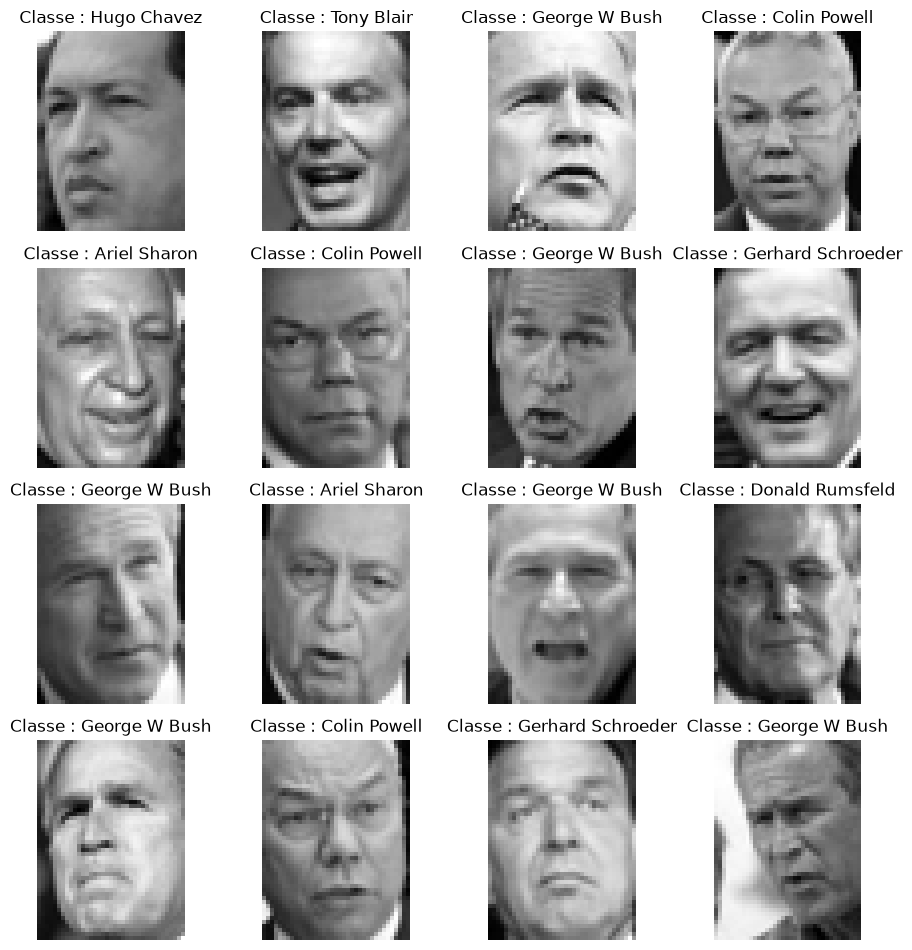

In [11]:
from sklearn.datasets import fetch_lfw_people

visages = fetch_lfw_people(
    resize=0.4,
    min_faces_per_person=70,
    color=False,
    download_if_missing=True,
)
images_visages = visages.images
labels_visages = visages.target
noms_personnes = visages.target_names

classes, effectifs = np.unique(labels_visages, return_counts=True)
print(f"Nombre d'images : {len(images_visages)}")
print(f"Taille d'une image : {images_visages.shape[1]} x {images_visages.shape[2]} pixels")
print(f"Nombre de personnes : {len(classes)}")
print("Images par personne :", dict(zip(noms_personnes, effectifs)))

labels_visages_noms = [noms_personnes[indice] for indice in labels_visages]
plot(images_visages, labels_visages_noms, normalize=True, n_images=16)

### Préparer les images de visages

Comme pour les chiffres, chaque image devient un vecteur de pixels. La différence est la taille : après réduction, chaque image contient encore beaucoup plus de caractéristiques qu'une vignette `8 × 8`.

In [12]:
X_visages = reshape(images_visages)
y_visages = labels_visages
print(f"Matrice X : {X_visages.shape[0]} images × {X_visages.shape[1]} pixels")
print(f"Vecteur y : {y_visages.shape[0]} identités")

Matrice X : 1288 images × 1850 pixels
Vecteur y : 1288 identités


### Séparer avant d'apprendre le prétraitement

La standardisation et l'ACP calculent des paramètres à partir des données. Il faut donc séparer les observations avant ces transformations. Nous les placerons dans un pipeline : à chaque pli de validation croisée, elles seront ajustées uniquement sur le sous-ensemble d'entraînement correspondant.

In [13]:
X_train_visages, X_test_visages, y_train_visages, y_test_visages = train_test_split(
    X_visages,
    y_visages,
    test_size=0.3,
    random_state=42,
    stratify=y_visages,
)

print(f"Entraînement : {X_train_visages.shape[0]} images")
print(f"Test final : {X_test_visages.shape[0]} images")

Entraînement : 901 images
Test final : 387 images


### Standardisation, ACP et SVM dans un pipeline

Les pixels d'une photo n'ont pas tous la même échelle ni la même importance. `StandardScaler` centre et met à l'échelle les caractéristiques ; l'ACP compresse ensuite les milliers de pixels en 100 composantes. Enfin, le SVM classe ces représentations.

L'ordre est important : le pipeline ajuste scaler et ACP uniquement sur les données qui servent à entraîner chaque pli, ce qui évite une fuite d'information vers la validation ou le test.

In [14]:
from sklearn.preprocessing import StandardScaler

pipeline_visages = Pipeline(
    steps=[
        ("standardisation", StandardScaler()),
        ("acp", PCA(
            n_components=100,
            svd_solver="randomized",
            whiten=True,
            random_state=42,
        )),
        ("svm", svm.SVC(class_weight="balanced")),
    ]
)

print("Pipeline prêt : StandardScaler → ACP (100 composantes) → SVC")

Pipeline prêt : StandardScaler → ACP (100 composantes) → SVC


### Comparer quelques réglages par validation croisée

Le noyau linéaire cherche une séparation par hyperplan ; le noyau RBF peut représenter des frontières courbes. `C` contrôle la pénalisation des erreurs et `gamma` l'influence locale des exemples pour le noyau RBF.

On teste une petite grille de paramètres avec une validation croisée stratifiée sur l'entraînement. Le score **F1 macro** donne le même poids à chaque identité, même si certaines sont plus fréquentes. Le jeu de test n'intervient pas dans ce choix.

In [15]:
grille_parametres = [
    {"svm__kernel": ["linear"], "svm__C": [0.1, 1, 10]},
    {
        "svm__kernel": ["rbf"],
        "svm__C": [1, 10],
        "svm__gamma": ["scale", 0.001],
    },
]
cv_visages = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
recherche = GridSearchCV(
    estimator=pipeline_visages,
    param_grid=grille_parametres,
    scoring="f1_macro",
    cv=cv_visages,
    n_jobs=-1,
    refit=True,
    return_train_score=False,
)

debut = time.perf_counter()
recherche.fit(X_train_visages, y_train_visages)
duree = time.perf_counter() - debut

print("Meilleurs paramètres :", recherche.best_params_)
print(f"Meilleur F1 macro en CV : {recherche.best_score_:.3f}")
print(f"Durée de la recherche : {duree:.1f} s")

resultats_tries = sorted(
    zip(
        recherche.cv_results_["rank_test_score"],
        recherche.cv_results_["mean_test_score"],
        recherche.cv_results_["std_test_score"],
        recherche.cv_results_["params"],
    ),
    key=lambda resultat: resultat[0],
)
print("\nMeilleurs essais :")
for rang, moyenne, ecart_type, parametres in resultats_tries[:5]:
    print(
        f"Rang {rang} : F1 macro = {moyenne:.3f} "
        f"(+/- {ecart_type:.3f}) | {parametres}"
    )

Meilleurs paramètres : {'svm__C': 1, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}
Meilleur F1 macro en CV : 0.757
Durée de la recherche : 3.8 s

Meilleurs essais :
Rang 1 : F1 macro = 0.757 (+/- 0.019) | {'svm__C': 1, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}
Rang 2 : F1 macro = 0.755 (+/- 0.016) | {'svm__C': 10, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}
Rang 3 : F1 macro = 0.752 (+/- 0.016) | {'svm__C': 1, 'svm__gamma': 0.001, 'svm__kernel': 'rbf'}
Rang 4 : F1 macro = 0.743 (+/- 0.029) | {'svm__C': 10, 'svm__gamma': 0.001, 'svm__kernel': 'rbf'}
Rang 5 : F1 macro = 0.707 (+/- 0.033) | {'svm__C': 0.1, 'svm__kernel': 'linear'}


### Évaluer une fois sur le test final

La recherche a déjà choisi ses paramètres à partir de `X_train_visages`. On applique maintenant le meilleur pipeline au test, une seule fois. Le rapport donne les métriques par personne ; la matrice aide à repérer les identités souvent confondues.

Rapport de classification sur le test final :
                   precision    recall  f1-score   support

     Ariel Sharon       1.00      0.78      0.88        23
     Colin Powell       0.72      0.96      0.82        71
  Donald Rumsfeld       0.90      0.70      0.79        37
    George W Bush       0.87      0.93      0.90       159
Gerhard Schroeder       0.77      0.70      0.73        33
      Hugo Chavez       1.00      0.57      0.73        21
       Tony Blair       0.94      0.72      0.82        43

         accuracy                           0.84       387
        macro avg       0.88      0.77      0.81       387
     weighted avg       0.86      0.84      0.84       387



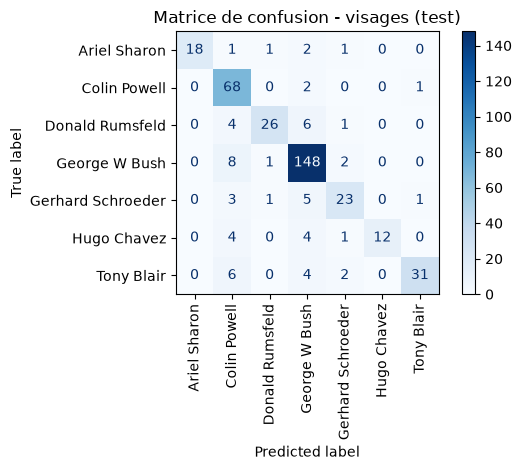

In [16]:
from sklearn.metrics import ConfusionMatrixDisplay

modele_visages_final = recherche.best_estimator_
prediction_visages = modele_visages_final.predict(X_test_visages)
labels_visages = np.arange(len(noms_personnes))

print("Rapport de classification sur le test final :")
print(
    classification_report(
        y_test_visages,
        prediction_visages,
        labels=labels_visages,
        target_names=noms_personnes,
        zero_division=0,
    )
)

matrice_visages = ConfusionMatrixDisplay.from_predictions(
    y_test_visages,
    prediction_visages,
    labels=labels_visages,
    display_labels=noms_personnes,
    cmap="Blues",
    xticks_rotation=90,
    values_format="d",
)
matrice_visages.ax_.set_title("Matrice de confusion - visages (test)")
plt.tight_layout()
plt.show()

### Interpréter le test final

Le rapport de classification présente, pour chaque identité, la précision, le rappel et le F1. La moyenne **macro** donne le même poids à chaque personne ; la moyenne **pondérée** tient compte de leur nombre d'images. La matrice de confusion place les bonnes prédictions sur la diagonale et les confusions hors diagonale.

La recherche de paramètres a utilisé uniquement la validation croisée sur l'entraînement. Le test final sert à estimer la performance sur des images non utilisées pour choisir le modèle ; il ne faut donc pas s'en servir ensuite pour modifier la grille ou choisir le noyau. Les résultats restent propres à ce découpage et à ce jeu de données.